Ce notebook presente le modele KNN pour la variable cible 'TousAge_allergie_urgences'


In [82]:
import pandas as pd
import numpy as np

Merge_final = pd.read_csv("../data/final_metropole/Merge_final.csv")

Merge_final.info()

Merge_final.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 76 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

C:\Users\gauxm\AppData\Local\Temp\ipykernel_30448\4033532219.py:4: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  Merge_final = pd.read_csv("../data/final_metropole/Merge_final.csv")


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,101586.607143,13.928571,258.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,102439.285714,14.285714,191.071429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,101053.392857,-43.392857,170.178571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,101230.000000,-12.500000,193.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,100684.107143,6.250000,162.857143,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


In [83]:
#NA
valeurs_manquantes = Merge_final.isnull().sum()
print(valeurs_manquantes[valeurs_manquantes > 0])

# Vérification du nombre de départements et de semaines
print(f"\nNombre de départements uniques : {Merge_final['code_dept'].unique()}")
print(f"Nombre de semaines uniques     : {Merge_final['date_semaine'].unique()}")


0an_bronchiolite_urgences             60
TousAge_allergie_hospitalisation      76
65plus_allergie_hospitalisation      106
0_14_allergie_hospitalisation        254
15_64_allergie_hospitalisation       118
0_14_asthme_hospitalisation          254
15_64_asthme_hospitalisation         118
TousAge_asthme_hospitalisation        76
65plus_asthme_hospitalisation        106
0an_bronchiolite_hospitalisation    1335
dtype: int64

Nombre de départements uniques : ['01' '02' '03' '04' '05' '06' '07' '08' '09' '10' '11' '12' '13' '14'
 '15' '16' '17' '18' '19' '21' '22' '23' '24' '25' '26' '27' '28' '29'
 '2A' '2B' '30' '31' '32' '33' '34' '35' '36' '37' '38' '39' 39 40 41 42
 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66
 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90
 91 92 93 94 95]
Nombre de semaines uniques     : <StringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S1

In [ ]:
#retire les colonne inutile
Merge_final_FS_MLA = Merge_final.drop(columns=[
    'precipitation_1h', 'precipitation_6h', 'precipitation_12h', 'precipitation_24h', 'periode_rafale',
    '0an_bronchiolite_urgences', 
    '65plus_allergie_urgences',
    '0_14_allergie_urgences',
    '15_64_allergie_urgences',
    '0_14_asthme_urgences',
    '15_64_asthme_urgences',
    'TousAge_asthme_urgences',
    '65plus_asthme_urgences',
    '0an_bronchiolite_hospitalisation',
    'TousAge_allergie_hospitalisation',
    '65plus_allergie_hospitalisation',
    '0_14_allergie_hospitalisation',
    '15_64_allergie_hospitalisation',
    '0_14_asthme_hospitalisation',
    '15_64_asthme_hospitalisation',
    'TousAge_asthme_hospitalisation',
    '65plus_asthme_hospitalisation',
    'Ntop_Maladie_Respi_Chronique_tsage_9',
    'Npop_Maladie_Respi_Chronique_tsage_9',
    'Ntop_Maladie_Respi_Chronique_0-14_9',
    'Ntop_Maladie_Respi_Chronique_15-64_9',
    'Ntop_Maladie_Respi_Chronique_65+_9',
    'Npop_Maladie_Respi_Chronique_0-14_9',
    'Npop_Maladie_Respi_Chronique_15-64_9',
    'Npop_Maladie_Respi_Chronique_65+_9',
    'nom_dep',])

Merge_final_FS_MLA.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 45 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

In [ ]:
#Met dans le bon type les variables
Merge_final_FS_MLA["code_dept"] = Merge_final_FS_MLA["code_dept"].astype("str")

Merge_final_FS_MLA['sos_present'] = Merge_final_FS_MLA['sos_present'].astype(int)

Merge_final_FS_MLA.info()

Merge_final_FS_MLA.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 45 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,101586.607143,13.928571,258.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,102439.285714,14.285714,191.071429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,101053.392857,-43.392857,170.178571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,101230.000000,-12.500000,193.750000,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,100684.107143,6.250000,162.857143,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0


In [86]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Calcul des matrices de corrélation sur les variables numériques
corr_pearson_FS = Merge_final_FS_MLA.select_dtypes(include=['float64', 'int64']).corr(method='pearson')
corr_spearman_FS = Merge_final_FS_MLA.select_dtypes(include=['float64', 'int64']).corr(method='spearman')

# Création des sous-graphiques côte à côte
fig = make_subplots(
    rows=1, cols=2, 
    subplot_titles=('Corrélation de Pearson (Linéaire)', 'Corrélation de Spearman (Monotone)'),
    horizontal_spacing=0.1
)

# Ajout de la heatmap Pearson
fig.add_trace(
    go.Heatmap(
        z=corr_pearson_FS.values,
        x=corr_pearson_FS.columns,
        y=corr_pearson_FS.index,
        colorscale='RdBu',
        zmin=-1, zmax=1,
        colorbar=dict(len=0.75, y=0.5)
    ),
    row=1, col=1
)

# Ajout de la heatmap Spearman
fig.add_trace(
    go.Heatmap(
        z=corr_spearman_FS.values,
        x=corr_spearman_FS.columns,
        y=corr_spearman_FS.index,
        colorscale='RdBu',
        zmin=-1, zmax=1,
        showscale=False # On masque la seconde barre d'échelle pour plus de clarté
    ),
    row=1, col=2
)

# Mise en page globale
fig.update_layout(
    title_text="Exploration Interactive des Corrélations - Master Dataset",
    height=800,
    width=1500,
    template="plotly_white"
)

# Masquer les étiquettes de l'axe des abscisses pour la figure de droite (col=2)
fig.update_yaxes(showticklabels=False, row=1, col=2)

# Affichage du graphique interactif
fig.show()

Étape 1 : Préparation du DataFrame & Découpage Temporel

In [87]:
# Copie de travail depuis Merge_final_FS_MLA
df = Merge_final_FS_MLA.copy()

# Extraction de l'année (ex: "2021-S01" -> 2021 en prenant les 4 premiers caractères)
df['annee'] = (
    df['date_semaine'].astype(str).str[:4].astype(int)
)

# Split temporel strict
df_train = df[df['annee'] <= 2022]
df_val = df[df['annee'] == 2023]
df_test = df[df['annee'] == 2024]

df.info()

df_test.info()

df_test.head()


<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 46 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   pression_mer                                19968 non-null  float64
 8   tendance_pression_3h                        19968 non-null  float64
 9   vent_direction                              19968 non-null  float64
 10  vent_vitesse         

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,pression_mer,tendance_pression_3h,vent_direction,...,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee
156,2024-S01,01,0.667750,0.650833,0.086167,2.0555,0.003767,101195.178571,-0.535714,225.357143,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
157,2024-S02,01,0.509437,0.638333,0.061333,1.7920,0.002724,102400.535714,-5.357143,264.821429,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
158,2024-S03,01,0.741125,1.568333,0.096500,1.8685,0.004689,101461.250000,35.535714,221.071429,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
159,2024-S04,01,0.557813,1.220000,0.074167,1.9375,0.003691,103336.785714,-1.428571,163.750000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
160,2024-S05,01,0.704500,1.590000,0.141833,2.6190,0.004768,103423.035714,2.678571,180.178571,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024


Étape 2 : Feature Engineering (Inertie & Saisons)

In [ ]:
# Extraction du numéro de semaine
semaines = df['date_semaine'].astype(str).str.split('S').str[1].astype(float)

# Encodage cyclique (sinus / cosinus)
df['semaine_sin'] = np.sin(2 * np.pi * semaines / 52)
df['semaine_cos'] = np.cos(2 * np.pi * semaines / 52)
  
# Variable de retard (lag 1) par département dans l'ordre chronologique
df = df.sort_values(['code_dept', 'date_semaine'])
df['target_lag_1'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(1)

# Nettoyage de la première ligne historique par département (qui a un NaN sur le lag)
df = df.dropna(subset=['target_lag_1'])

# Mise à jour des splits Train / Val / Test avec les nouvelles features
df_train = df[df['annee'] <= 2022].copy()
df_val = df[df['annee'] == 2023].copy()
df_test = df[df['annee'] == 2024].copy()

# Vérification rapide
print(f'Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}')


Train : (9888, 49) | Val : (4992, 49) | Test : (4992, 49)


Étape 3 : Preprocessing pour KNN

In [89]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#Colonnes à exclure des features (X)
cols_to_drop = ['TousAge_allergie_urgences', 'date_semaine', 'annee']
cols_to_drop = [c for c in cols_to_drop if c in df.columns]

# Séparation X / y pour chaque split
X_train = df_train.drop(columns=cols_to_drop)
y_train = df_train['TousAge_allergie_urgences']

X_val = df_val.drop(columns=cols_to_drop)
y_val = df_val['TousAge_allergie_urgences']

X_test = df_test.drop(columns=cols_to_drop)
y_test = df_test['TousAge_allergie_urgences']

# Identification explicite des colonnes catégorielles et numériques
cat_cols = ['code_dept']
num_cols = [c for c in X_train.columns if c not in cat_cols]

print(f'Colonnes numériques ({len(num_cols)}) : {num_cols}')
print(f'Colonnes catégorielles ({len(cat_cols)}) : {cat_cols}')

# Construction du préprocesseur pour le KNN
preprocessor_knn = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ]
)

# Application (Fit sur le Train uniquement, Transform sur Val et Test)
X_train_knn = preprocessor_knn.fit_transform(X_train)
X_val_knn = preprocessor_knn.transform(X_val)
X_test_knn = preprocessor_knn.transform(X_test)

print('\nDimensions après preprocessing KNN :')
print(f'X_train_knn : {X_train_knn.shape}')
print(f'X_val_knn   : {X_val_knn.shape}')
print(f'X_test_knn  : {X_test_knn.shape}')

Colonnes numériques (45) : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines', 'sos_presen

Étape 4 : Calcul des Baselines sur Train, Val et Test 

In [90]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fonction d'affichage rapide pour standardiser les résultats
def eval_metrics(y_true, y_pred, name_split, name_baseline):
  r2 = r2_score(y_true, y_pred)
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mae = mean_absolute_error(y_true, y_pred)
  print(
      f'[{name_baseline}] {name_split} -> R2: {r2:.4f} | RMSE: {rmse:.4f} |'
      f' MAE: {mae:.4f}'
  )

##Baseline persistance
# La prédiction est simplement la variable target_lag_1
eval_metrics(y_train, X_train['target_lag_1'], 'Train', 'Persistance')
eval_metrics(y_val, X_val['target_lag_1'], 'Val (2023)', 'Persistance')
eval_metrics(y_test, X_test['target_lag_1'], 'Test (2024)', 'Persistance')

##baseline Moyenne historique
# Extraction du numéro de semaine (ex: "2021-S01" -> 1.0) pour le calcul historique
df_train_copy = df_train.copy()
df_train_copy['semaine_num'] = (
    df_train_copy['date_semaine'].astype(str).str.split('S').str[1].astype(float)
)

# Calcul de la moyenne par (code_dept, semaine_num) uniquement sur le Train (2021-2022)
moy_hist = (
    df_train_copy.groupby(['code_dept', 'semaine_num'])[
        'TousAge_allergie_urgences'
    ]
    .mean()
    .reset_index()
)

# Fonction interne pour assigner la moyenne historique à n'importe quel split
def get_moy_hist_preds(data_split):
  temp = data_split.copy()
  temp['semaine_num'] = (
      temp['date_semaine'].astype(str).str.split('S').str[1].astype(float)
  )
  merged = temp.merge(
      moy_hist, on=['code_dept', 'semaine_num'], how='left', suffixes=('', '_moy')
  )
  # Si une combinaison département/semaine n'existe pas dans le train, on remplace par la moyenne globale du train
  return merged['TousAge_allergie_urgences_moy'].fillna(y_train.mean())


# Évaluation de la moyenne historique sur les 3 splits
eval_metrics(y_train, get_moy_hist_preds(df_train), 'Train', 'Moyenne Hist.')
eval_metrics(y_val, get_moy_hist_preds(df_val), 'Val (2023)', 'Moyenne Hist.')
eval_metrics(y_test, get_moy_hist_preds(df_test), 'Test (2024)', 'Moyenne Hist.')

[Persistance] Train -> R2: 0.0719 | RMSE: 310.8454 | MAE: 222.9904
[Persistance] Val (2023) -> R2: 0.1041 | RMSE: 306.1080 | MAE: 219.0278
[Persistance] Test (2024) -> R2: 0.0348 | RMSE: 287.9188 | MAE: 206.7123
[Moyenne Hist.] Train -> R2: 0.6957 | RMSE: 177.9876 | MAE: 128.2105
[Moyenne Hist.] Val (2023) -> R2: 0.2480 | RMSE: 280.4511 | MAE: 203.9206
[Moyenne Hist.] Test (2024) -> R2: 0.0541 | RMSE: 285.0372 | MAE: 210.2151


Étape 5 : Entraînement & Optimisation des Modèles

In [91]:
from sklearn.metrics import r2_score
from sklearn.neighbors import KNeighborsRegressor

best_val_r2 = -float('inf')
best_knn = None
best_params_knn = {}

# Grille de recherche manuelle
for k in [1, 3, 5, 7, 10, 15, 20, 25, 30]:
  for w in ['uniform', 'distance']:
    for p_val in [1, 2]:  # 1 = Manhattan, 2 = Euclidienne
      # Initialisation et entraînement sur le Train prétraité
      knn = KNeighborsRegressor(n_neighbors=k, weights=w, p=p_val)
      knn.fit(X_train_knn, y_train)

      # Évaluation sur la Validation (2023)
      y_val_pred = knn.predict(X_val_knn)
      r2_val_score = r2_score(y_val, y_val_pred)

      # Sauvegarde si c'est la meilleure combinaison
      if r2_val_score > best_val_r2:
        best_val_r2 = r2_val_score
        best_knn = knn
        best_params_knn = {'n_neighbors': k, 'weights': w, 'p': p_val}

print(f'Meilleurs paramètres KNN trouvés : {best_params_knn}')
print(f'Meilleur R2 sur Validation (2023) : {best_val_r2:.4f}\n')

# Comparaison Train vs Val pour valider l'absence de surapprentissage
print('--- Performances du meilleur KNN (Train vs Val) ---')
eval_metrics(y_train, best_knn.predict(X_train_knn), 'Train', 'KNN Optimal')
eval_metrics(y_val, best_knn.predict(X_val_knn), 'Val (2023)', 'KNN Optimal')


Meilleurs paramètres KNN trouvés : {'n_neighbors': 20, 'weights': 'distance', 'p': 1}
Meilleur R2 sur Validation (2023) : 0.4376

--- Performances du meilleur KNN (Train vs Val) ---
[KNN Optimal] Train -> R2: 1.0000 | RMSE: 0.0000 | MAE: 0.0000
[KNN Optimal] Val (2023) -> R2: 0.4376 | RMSE: 242.5183 | MAE: 178.9520


Étape 6 : Validation Finale sur Test (2024)

In [ ]:
# Prédiction et évaluation du meilleur KNN sur le Test
y_test_pred_knn = best_knn.predict(X_test_knn)
eval_metrics(y_test, y_test_pred_knn, 'Test (2024)', 'KNN Optimal')

# Comparaison directe avec les Baselines sur le Test
print('Comparaison avec les Baselines (Test 2024)')
eval_metrics(y_test, X_test['target_lag_1'], 'Test (2024)', 'Persistance (t-1)')
eval_metrics(y_test, get_moy_hist_preds(df_test), 'Test (2024)', 'Moyenne Historique')


[KNN Optimal] Test (2024) -> R2: 0.3603 | RMSE: 234.4019 | MAE: 174.4797

--- Comparaison avec les Baselines (Test 2024) ---
[Persistance (t-1)] Test (2024) -> R2: 0.0348 | RMSE: 287.9188 | MAE: 206.7123
[Moyenne Historique] Test (2024) -> R2: 0.0541 | RMSE: 285.0372 | MAE: 210.2151


Étape 7 : représentation résultats et comparaison entre prédict et réel

1. Tableau comparatif direct des valeurs réelles et prédites pour chaque département et chaque semaine de 2024, avec le calcul de l'erreur absolue

In [93]:
import pandas as pd

# Création du DataFrame de comparaison
df_comparison = pd.DataFrame({
    'date_semaine': df_test['date_semaine'].values,
    'code_dept': df_test['code_dept'].values,
    'reel': y_test.values,
    'pred_knn': y_test_pred_knn,
})

# Calcul de l'écart absolu
df_comparison['ecart_absolu'] = abs(
    df_comparison['reel'] - df_comparison['pred_knn']
)

# Affichage des 10 premières lignes
print(df_comparison.head(15))

   date_semaine code_dept        reel    pred_knn  ecart_absolu
0      2024-S01        01  613.732259  539.380515     74.351744
1      2024-S02        01  341.442595  537.529743    196.087149
2      2024-S03        01  573.394495  515.756984     57.637512
3      2024-S04        01  436.046512  515.732883     79.686371
4      2024-S05        01  643.695570  492.399601    151.295969
5      2024-S06        01  669.027942  536.368756    132.659186
6      2024-S07        01  260.610573  585.197531    324.586957
7      2024-S08        01  374.220374  580.579706    206.359332
8      2024-S09        01  649.631875  617.077026     32.554849
9      2024-S10        01  397.140588  582.382381    185.241793
10     2024-S11        01  420.328621  634.279604    213.950983
11     2024-S12        01  556.173526  689.632728    133.459202
12     2024-S13        01  395.726157  621.152471    225.426314
13     2024-S14        01  463.499421  727.177138    263.677717
14     2024-S15        01  606.520091  7

2. Visualisation graphique: un scatter plot global (pour voir la dispersion) et une courbe temporelle (pour suivre l'évolution sur un département cible, par exemple les Bouches-du-Rhône 13).

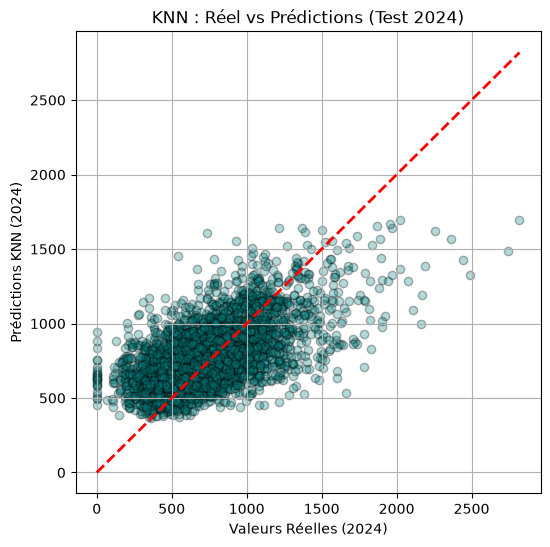

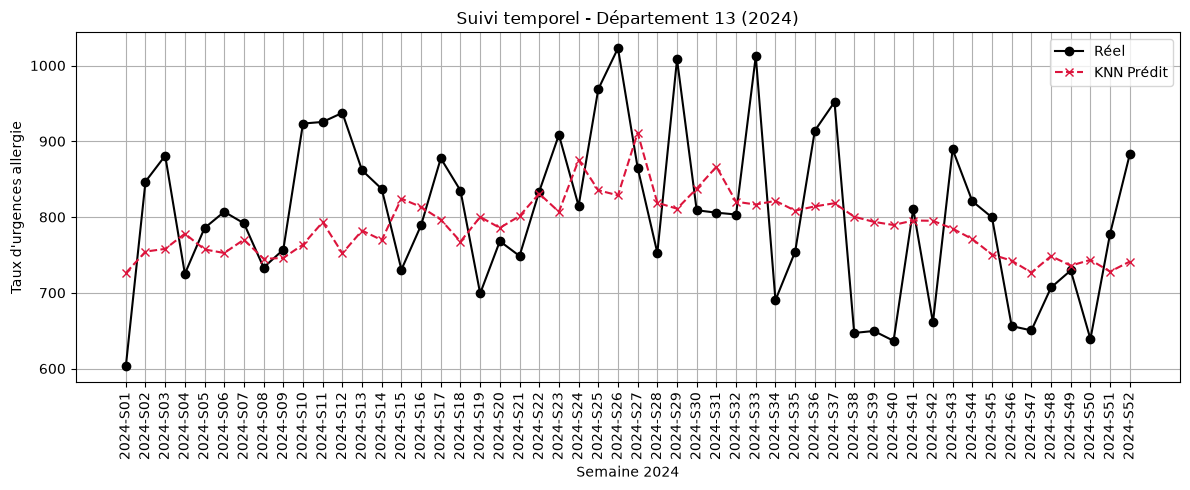

In [ ]:
import matplotlib.pyplot as plt

# Scatter Plot : Réel vs Prédit (Global 2024)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_test_pred_knn, alpha=0.3, color='teal', edgecolor='k')

# Ligne idéale y = x
plt.plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2
)
plt.xlabel('Valeurs Réelles (2024)')
plt.ylabel('Prédictions KNN (2024)')
plt.title('KNN : Réel vs Prédictions (Test 2024)')
plt.grid(True)
plt.show()

# Courbe temporelle sur un département spécifique (ex: Bouches-du-Rhône '13')
dept_cible = (
    '13' if '13' in df_test['code_dept'].values else df_test['code_dept'].iloc[0]
)
sub_df = df_comparison[df_comparison['code_dept'] == dept_cible].sort_values(
    'date_semaine'
)

plt.figure(figsize=(12, 5))
plt.plot(
    sub_df['date_semaine'],
    sub_df['reel'],
    label='Réel',
    color='black',
    marker='o',
    lw=1.5,
)
plt.plot(
    sub_df['date_semaine'],
    sub_df['pred_knn'],
    label='KNN Prédit',
    color='crimson',
    linestyle='--',
    marker='x',
    lw=1.5,
)
plt.xticks(rotation=90)
plt.xlabel('Semaine 2024')
plt.ylabel("Taux d'urgences allergie")
plt.title(f"Suivi temporel - Département {dept_cible} (2024)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()